In [1]:
pip install mne numpy matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 48.4 MB/s eta 0:00:00


In [2]:
pip install mne-connectivity


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.2/115.2 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 65.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 51.8 MB/s eta 0:00:00


In [3]:
import mne
from mne_connectivity import spectral_connectivity_epochs
import matplotlib.pyplot as plt
import numpy as np


In [4]:
from google.colab import drive
drive.mount('/content/drive')
edf_path = '/content/drive/MyDrive/EEG_Processing_Python/SUB_01.edf'
raw = mne.io.read_raw_edf(edf_path, preload=True)
raw.pick_types(eeg=True)  # Only EEG channels

# View basic info
print(raw.info)
raw.filter(1., 40., fir_design='firwin')  # Band-pass filter

Mounted at /content/drive
Extracting EDF parameters from /content/drive/MyDrive/EEG_Processing_Python/SUB_01.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 183599  =      0.000 ...   367.198 secs...
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
<Info | 8 non-empty values
 bads: []
 ch_names: Trig, Fp1-LE, Fp2-LE, F3-LE, F4-LE, C3-LE, C4-LE, P3-LE, P4-LE, ...
 chs: 20 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 250.0 Hz
 meas_date: 2025-02-25 22:59:29 UTC
 nchan: 20
 projs: []
 sfreq: 500.0 Hz
 subject_info: <subject_info | his_id: Azam>
>
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower t

<RawEDF | SUB_01.edf, 20 x 183600 (367.2 s), ~28.0 MiB, data loaded>

In [5]:

# ------------------- Create Epochs -------------------
events = mne.make_fixed_length_events(raw, duration=2.0)  # Use fixed 2s windows
epochs = mne.Epochs(raw, events, tmin=0, tmax=2.0, baseline=None, preload=True)

Not setting metadata
183 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 183 events and 1001 original time points ...
0 bad epochs dropped


In [6]:

# ------------------- Compute Connectivity -------------------
# Compute spectral connectivity (returns one object, not a tuple)
con = spectral_connectivity_epochs(
    data=epochs,
    method='coh',
    mode='multitaper',
    sfreq=raw.info['sfreq'],
    fmin=8., fmax=13.,  # Alpha band
    faverage=True,
    tmin=0.0, tmax=2.0,
    verbose=True
)

# Extract the connectivity matrix
con_matrix = con.get_data(output='dense')[:, :, 0]  # (n_channels, n_channels)

# Get channel names
ch_names = con.names

Adding metadata with 3 columns
Connectivity computation...
only using indices for lower-triangular matrix
    computing connectivity for 190 connections
    using t=0.000s..2.000s for estimation (1001 points)
    frequencies: 8.5Hz..13.0Hz (10 points)
    connectivity scores will be averaged for each band
    Using multitaper spectrum estimation with 7 DPSS windows
    the following metrics will be computed: Coherence
    computing cross-spectral density for epoch 1
    computing cross-spectral density for epoch 2
    computing cross-spectral density for epoch 3
    computing cross-spectral density for epoch 4
    computing cross-spectral density for epoch 5
    computing cross-spectral density for epoch 6
    computing cross-spectral density for epoch 7
    computing cross-spectral density for epoch 8
    computing cross-spectral density for epoch 9
    computing cross-spectral density for epoch 10
    computing cross-spectral density for epoch 11
    computing cross-spectral density 

/usr/local/lib/python3.11/dist-packages/mne_connectivity/spectral/epochs_bivariate.py:81: RuntimeWarning: invalid value encountered in divide
  self.con_scores[con_idx] = np.abs(csd_mean) / np.sqrt(psd_xx * psd_yy)


[Connectivity computation done]


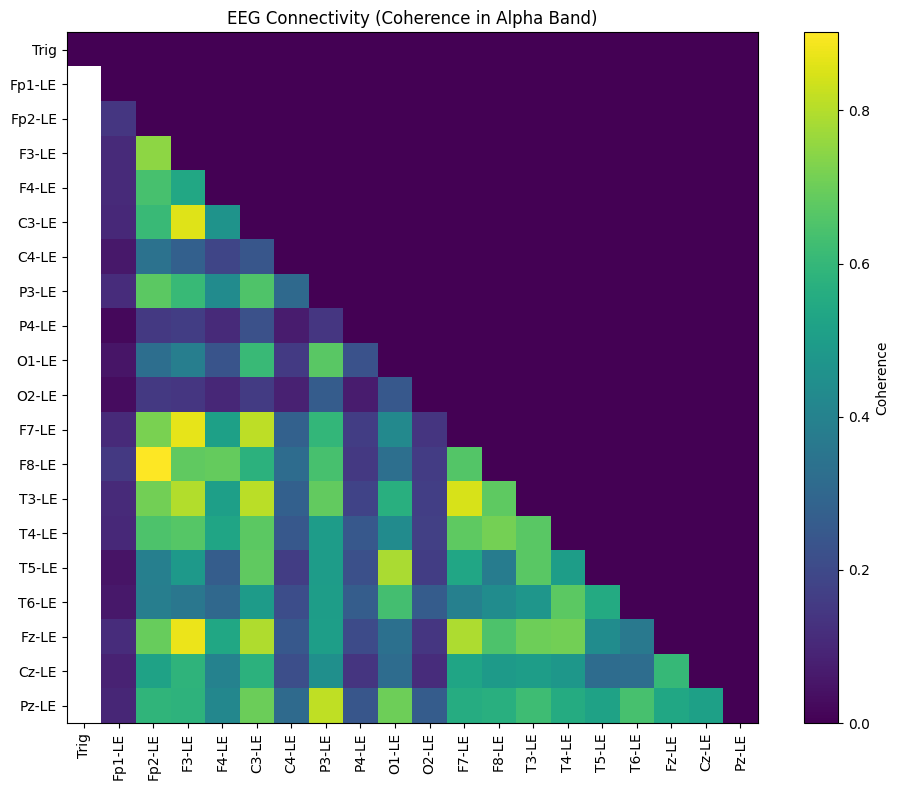

In [7]:

# Plotting
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 8))
im = plt.imshow(con_matrix, interpolation='nearest', cmap='viridis')
plt.title('EEG Connectivity (Coherence in Alpha Band)')
plt.colorbar(im, label='Coherence')
plt.xticks(np.arange(len(ch_names)), labels=ch_names, rotation=90)
plt.yticks(np.arange(len(ch_names)), labels=ch_names)
plt.tight_layout()
plt.show()


In [9]:
pip install networkx bctpy numpy


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 110.4/110.4 kB 2.9 MB/s eta 0:00:00


In [11]:
import numpy as np
import networkx as nx
from networkx.exception import PowerIterationFailedConvergence

# ----------------------------
# Load your connectivity matrix
# Replace this with your actual matrix
# ----------------------------
conn_matrix = np.random.rand(10, 10)
np.fill_diagonal(conn_matrix, 0)  # No self-connections

# ----------------------------
# Build undirected weighted graph
# ----------------------------
G = nx.from_numpy_array(conn_matrix)

# ----------------------------
# Node-level metrics
# ----------------------------
degree_dict = dict(G.degree(weight=None))  # unweighted degree
strength_dict = dict(G.degree(weight='weight'))  # weighted degree

clustering_dict = nx.clustering(G, weight='weight')
betweenness_dict = nx.betweenness_centrality(G, weight='weight')

# Safe eigenvector centrality
try:
    eigenvector_dict = nx.eigenvector_centrality(G, weight='weight', max_iter=5000, tol=1e-06)
except PowerIterationFailedConvergence:
    print("Eigenvector centrality failed to converge, using numpy eig instead.")
    A = nx.to_numpy_array(G, weight='weight')
    eigvals, eigvecs = np.linalg.eig(A)
    max_index = np.argmax(np.abs(eigvals))
    eigenvector_centrality = np.abs(eigvecs[:, max_index])
    eigenvector_dict = dict(zip(G.nodes, eigenvector_centrality))

# Local efficiency
local_efficiency_dict = {n: nx.local_efficiency(G.subgraph(G.neighbors(n)).copy()) for n in G.nodes()}

# ----------------------------
# Global/Network-level metrics
# ----------------------------
global_efficiency = nx.global_efficiency(G)
try:
    char_path_length = nx.average_shortest_path_length(G, weight='weight')
except:
    char_path_length = None  # disconnected graph

modularity = None  # Not in networkx directly

# Small-worldness (approximate)
clustering_avg = nx.average_clustering(G, weight='weight')
try:
    random_graph = nx.erdos_renyi_graph(n=len(G.nodes), p=0.5)
    small_worldness = clustering_avg / nx.average_shortest_path_length(random_graph)
except:
    small_worldness = None

assortativity = nx.degree_assortativity_coefficient(G)
density = nx.density(G)
transitivity = nx.transitivity(G)

# ----------------------------
# Print sample results
# ----------------------------
print("Degree:", degree_dict)
print("Strength:", strength_dict)
print("Clustering Coefficient:", clustering_dict)
print("Betweenness Centrality:", betweenness_dict)
print("Eigenvector Centrality:", eigenvector_dict)
print("Local Efficiency:", local_efficiency_dict)
print("Global Efficiency:", global_efficiency)
print("Characteristic Path Length:", char_path_length)
print("Small-worldness:", small_worldness)
print("Assortativity:", assortativity)
print("Density:", density)
print("Transitivity:", transitivity)


Degree: {0: 9, 1: 9, 2: 9, 3: 9, 4: 9, 5: 9, 6: 9, 7: 9, 8: 9, 9: 9}
Strength: {0: 6.9849132912006695, 1: 5.307856528629563, 2: 4.625924061962438, 3: 5.8648047044074385, 4: 5.2280736841550794, 5: 5.130821103395824, 6: 6.432067890697717, 7: 4.486982079217574, 8: 6.026567711690879, 9: 6.07295790315998}
Clustering Coefficient: {0: 0.6784514746437335, 1: 0.5612317422439604, 2: 0.4935242491664505, 3: 0.6106808534999058, 4: 0.564151968674524, 5: 0.5640015864881247, 6: 0.6395942688283266, 7: 0.4910365179429024, 8: 0.6158989216873397, 9: 0.6314282828367025}
Betweenness Centrality: {0: 0.0, 1: 0.05555555555555555, 2: 0.4722222222222222, 3: 0.0, 4: 0.1388888888888889, 5: 0.1111111111111111, 6: 0.0, 7: 0.2777777777777778, 8: 0.0, 9: 0.0}
Eigenvector Centrality: {0: 0.3766474080737317, 1: 0.30518782829971014, 2: 0.27338089755235223, 3: 0.3282614402173418, 4: 0.2891167728787687, 5: 0.288898357115538, 6: 0.3589310700043724, 7: 0.25608376431028446, 8: 0.3330228499673942, 9: 0.331872017661701}
Local E

/usr/local/lib/python3.11/dist-packages/networkx/algorithms/assortativity/correlation.py:302: RuntimeWarning: invalid value encountered in scalar divide
  return float((xy * (M - ab)).sum() / np.sqrt(vara * varb))


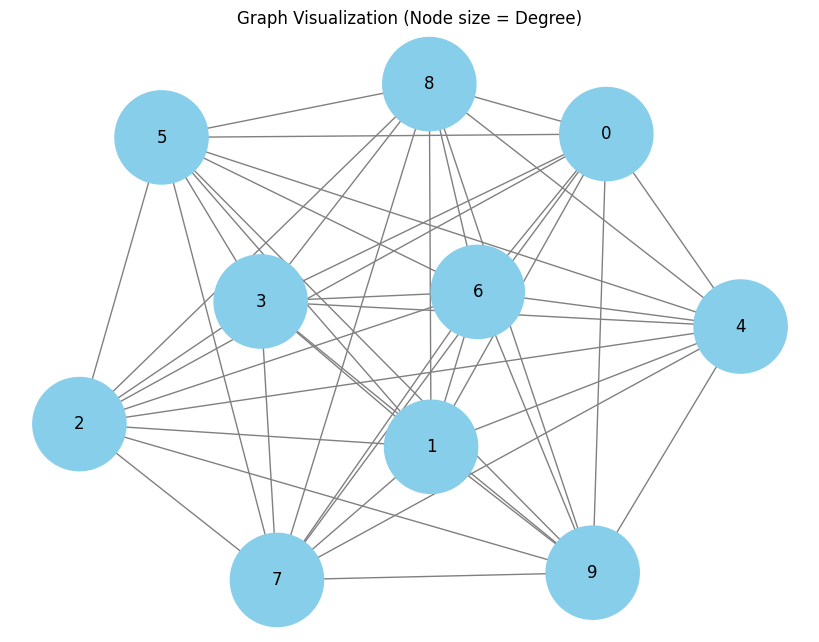

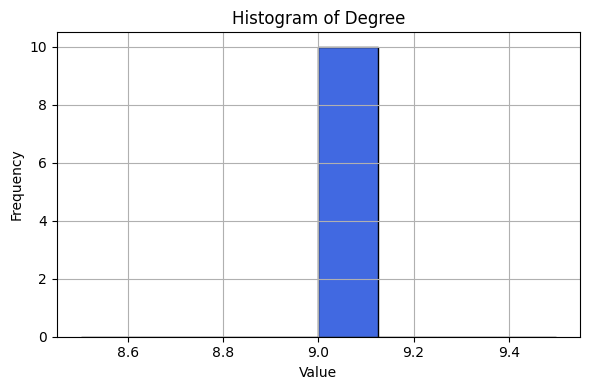

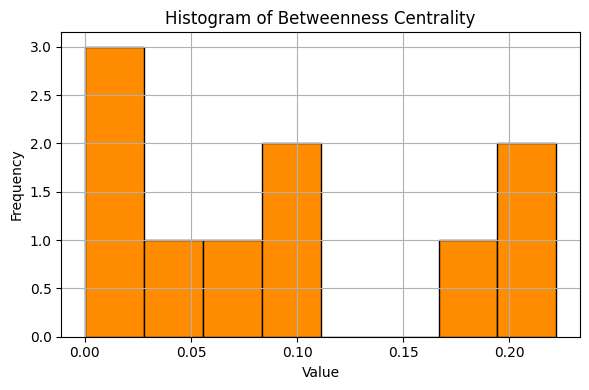

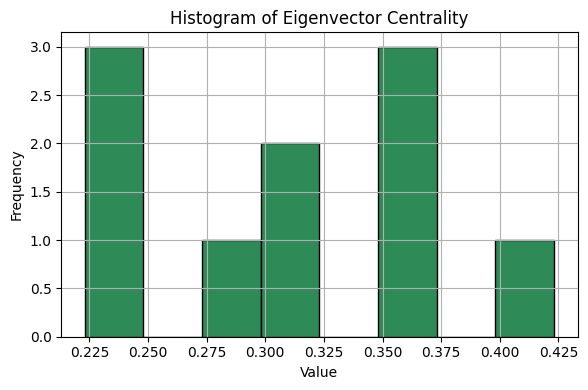

In [12]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from networkx.exception import PowerIterationFailedConvergence

# ----------------------------
# Load your connectivity matrix
conn_matrix = np.random.rand(10, 10)
np.fill_diagonal(conn_matrix, 0)

# ----------------------------
# Build graph
G = nx.from_numpy_array(conn_matrix)

# ----------------------------
# Node-level metrics
degree_dict = dict(G.degree(weight=None))
strength_dict = dict(G.degree(weight='weight'))
clustering_dict = nx.clustering(G, weight='weight')
betweenness_dict = nx.betweenness_centrality(G, weight='weight')

try:
    eigenvector_dict = nx.eigenvector_centrality(G, weight='weight', max_iter=5000, tol=1e-06)
except PowerIterationFailedConvergence:
    print("Eigenvector centrality failed to converge, fallback using numpy.")
    A = nx.to_numpy_array(G, weight='weight')
    eigvals, eigvecs = np.linalg.eig(A)
    max_index = np.argmax(np.abs(eigvals))
    eigenvector_centrality = np.abs(eigvecs[:, max_index])
    eigenvector_dict = dict(zip(G.nodes, eigenvector_centrality))

local_efficiency_dict = {n: nx.local_efficiency(G.subgraph(G.neighbors(n)).copy()) for n in G.nodes()}

# ----------------------------
# Plotting - 1: Network with degree size
plt.figure(figsize=(8, 6))
node_size = [v * 500 for v in degree_dict.values()]
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_size=node_size, node_color='skyblue', edge_color='gray')
plt.title("Graph Visualization (Node size = Degree)")
plt.show()

# ----------------------------
# Plotting - 2: Histograms
def plot_hist(data_dict, title, color):
    plt.figure(figsize=(6, 4))
    values = list(data_dict.values())
    plt.hist(values, bins=8, color=color, edgecolor='black')
    plt.title(title)
    plt.xlabel("Value")
    plt.ylabel("Frequency")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

plot_hist(degree_dict, "Histogram of Degree", "royalblue")
plot_hist(betweenness_dict, "Histogram of Betweenness Centrality", "darkorange")
plot_hist(eigenvector_dict, "Histogram of Eigenvector Centrality", "seagreen")


---

### 1. **Graph Visualization (Node size = Degree)**

* **What it shows:**
  Each node (EEG channel) is a circle, and the size of the circle represents how many direct connections (degree) that node has with others.

* **Interpretation:**

  * **Large nodes:** Channels with many connections — they are potentially hubs or important communication points in the brain network.
  * **Small nodes:** Channels with fewer connections — less “central” in the network.

* **Why useful:**
  Helps identify which brain regions (electrodes) are highly connected during your EEG recording.

---

### 2. **Histogram of Degree**

* **What it shows:**
  Distribution of the number of connections each node has.

* **Interpretation:**

  * If the histogram is skewed right with few nodes having very high degree, it means a few hubs dominate connectivity.
  * A more uniform distribution means connectivity is more evenly spread across brain regions.

---

### 3. **Histogram of Betweenness Centrality**

* **What it shows:**
  How often a node lies on shortest paths between other pairs of nodes — essentially a measure of “brokerage” or “bridge” roles.

* **Interpretation:**

  * Nodes with high betweenness centrality control information flow across the network.
  * If a few nodes have high values, they act as critical hubs connecting different brain areas.

---

### 4. **Histogram of Eigenvector Centrality**

* **What it shows:**
  Measures influence of a node, considering not only how many connections it has, but how important those connected nodes are.

* **Interpretation:**

  * High eigenvector centrality means a node is connected to other well-connected nodes — a sign of influential hubs.
  * Helps identify key brain regions involved in coordinated activity.


